# Home Loan Data Analysis
**Course-End Project, Deep Learning with Keras and TensorFlow**

Objective: build a deep learning model that predicts whether a loan applicant will have payment difficulties (`TARGET = 1`) or repay (`TARGET = 0`). The data is highly imbalanced and wide (122 columns), so the notebook covers loading, null checks, class balance, encoding, a Keras neural network, and evaluation with **sensitivity** and **ROC-AUC**.

*Run on CPU only; training is kept modest (balanced training subset, a few epochs).*

In [1]:
import os, json, warnings, random
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt, seaborn as sns
os.environ['TF_CPP_MIN_LOG_LEVEL']='3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve, recall_score,
                             precision_score, accuracy_score, f1_score, classification_report)
SEED=42; np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)
os.makedirs('screenshots', exist_ok=True)
def save(name): plt.savefig(f'screenshots/{name}.png', dpi=110, bbox_inches='tight')
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## Step 1: Load the dataset

In [2]:
df = pd.read_csv('data/Home_loan_data.csv')
print('Shape:', df.shape)
df.iloc[:5, :8]

Shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL
0,100002,1,Cash loans,M,N,Y,0,202500.0
1,100003,0,Cash loans,F,N,N,0,270000.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0
3,100006,0,Cash loans,F,N,Y,0,135000.0
4,100007,0,Cash loans,M,N,Y,0,121500.0


The file has 307,511 applications and 122 columns (`SK_ID_CURR` is an identifier, `TARGET` is the label).

## Step 2: Check for null values

Total null cells: 9152465
Columns with at least one null: 67 of 122
Columns with more than 40% null: 49
COMMONAREA_MEDI             69.87
COMMONAREA_MODE             69.87
COMMONAREA_AVG              69.87
NONLIVINGAPARTMENTS_MODE    69.43
NONLIVINGAPARTMENTS_MEDI    69.43
NONLIVINGAPARTMENTS_AVG     69.43
FONDKAPREMONT_MODE          68.39
LIVINGAPARTMENTS_AVG        68.35
LIVINGAPARTMENTS_MEDI       68.35
LIVINGAPARTMENTS_MODE       68.35
FLOORSMIN_MEDI              67.85
FLOORSMIN_MODE              67.85
FLOORSMIN_AVG               67.85
YEARS_BUILD_MODE            66.50
YEARS_BUILD_MEDI            66.50


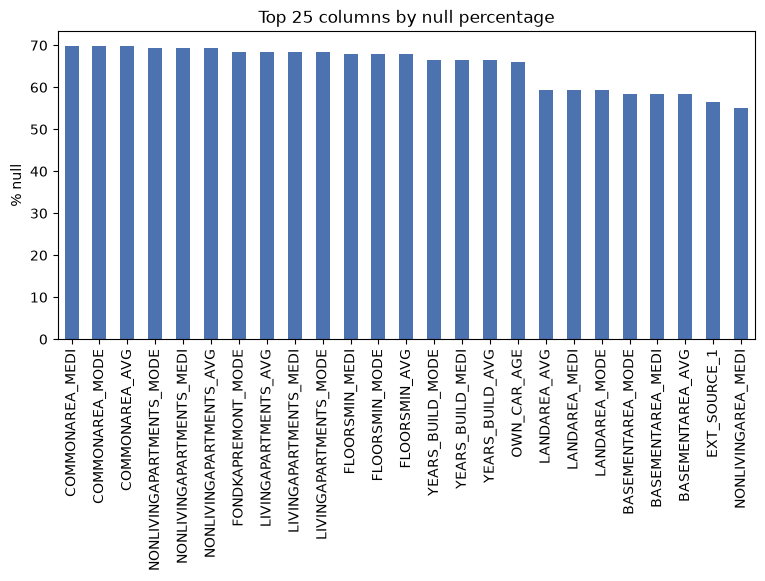

In [3]:
nulls = df.isnull().sum()
nulls = nulls[nulls>0].sort_values(ascending=False)
null_pct = (nulls/len(df)*100).round(2)
print('Total null cells:', int(df.isnull().sum().sum()))
print('Columns with at least one null:', len(nulls), 'of', df.shape[1])
print('Columns with more than 40% null:', int((null_pct>40).sum()))
print(null_pct.head(15).to_string())
plt.figure(figsize=(9,4)); null_pct.head(25).plot.bar(color='#4c72b0'); plt.ylabel('% null'); plt.title('Top 25 columns by null percentage'); save('01_null_percentage'); plt.show()

Many columns (mostly the building/housing descriptors) are 40-70% empty. We will drop columns that are more than 40% null and impute the rest.

## Step 3: Percentage of defaulters to payers (TARGET)

In [4]:
vc = df['TARGET'].value_counts(); pct = df['TARGET'].value_counts(normalize=True)*100
print(f"Payers (TARGET=0):    {vc[0]:>7,}  ({pct[0]:.2f}%)")
print(f"Defaulters (TARGET=1): {vc[1]:>7,}  ({pct[1]:.2f}%)")
print(f"Ratio payers : defaulters = {vc[0]/vc[1]:.1f} : 1")

Payers (TARGET=0):    282,686  (91.93%)
Defaulters (TARGET=1):  24,825  (8.07%)
Ratio payers : defaulters = 11.4 : 1


Only about 8% of applicants default, so the dataset is heavily imbalanced (about 11.4 payers per defaulter). A model predicting 'payer' for everyone would be 92% accurate yet useless, so accuracy is not a reliable metric here; we focus on sensitivity and ROC-AUC.

## Step 4: Plot the imbalanced data

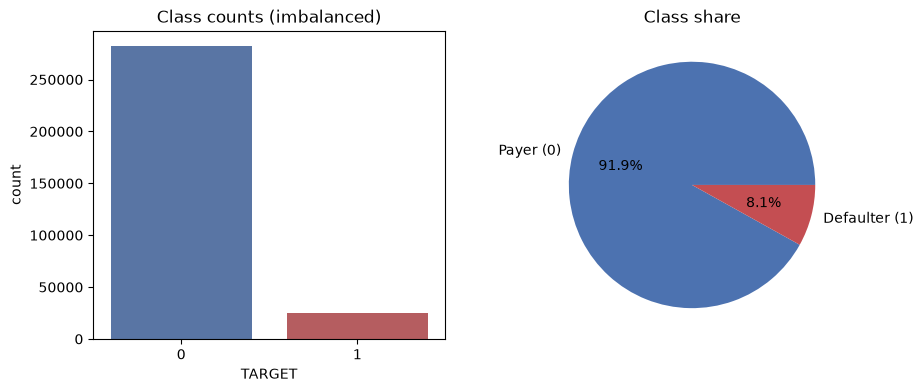

In [5]:
fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.countplot(x='TARGET', data=df, ax=ax[0], palette=['#4c72b0','#c44e52']); ax[0].set_title('Class counts (imbalanced)')
ax[1].pie(vc.values, labels=['Payer (0)','Defaulter (1)'], autopct='%1.1f%%', colors=['#4c72b0','#c44e52']); ax[1].set_title('Class share')
save('02_imbalanced_target'); plt.show()

## Step 5: Encode the required columns (preprocessing)
Steps: drop the id and the >40% null columns; impute numeric nulls with the median and categorical nulls with `'Unknown'`; encode categoricals (binary/low-cardinality columns one-hot encoded; the 58-level `ORGANIZATION_TYPE` label-encoded); then split into train/test **before** balancing so the test set stays realistic.

In [6]:
data = df.drop(columns=['SK_ID_CURR'])
data = data.drop(columns=null_pct[null_pct>40].index)
y = data.pop('TARGET').values
cat_cols = data.select_dtypes(exclude='number').columns.tolist()
num_cols = [c for c in data.columns if c not in cat_cols]
for c in num_cols: data[c] = data[c].fillna(data[c].median())
for c in cat_cols: data[c] = data[c].fillna('Unknown')
high_card = [c for c in cat_cols if data[c].nunique()>10]
for c in high_card: data[c] = data[c].astype('category').cat.codes   # label encoding
data = pd.get_dummies(data, columns=[c for c in cat_cols if c not in high_card], drop_first=True, dtype=int)
print('Label encoded:', high_card)
print('Final feature matrix:', data.shape, '| remaining nulls:', int(data.isnull().sum().sum()))

Label encoded: ['OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
Final feature matrix: (307511, 100) | remaining nulls: 0


In [7]:
X_tr, X_te, y_tr, y_te = train_test_split(data.values.astype('float32'), y, test_size=0.2, stratify=y, random_state=SEED)
scaler = StandardScaler().fit(X_tr); X_tr = scaler.transform(X_tr); X_te = scaler.transform(X_te)
print('Train:', X_tr.shape, 'defaulters %.2f%%' % (y_tr.mean()*100), '| Test:', X_te.shape, 'defaulters %.2f%%' % (y_te.mean()*100))

Train: (246008, 100) defaulters 8.07% | Test: (61503, 100) defaulters 8.07%


## Step 6: Balance the dataset
The data is imbalanced, so the **training** set is balanced by random under-sampling of the majority class (SMOTE on 245k rows x 200 features is too slow for a CPU run; under-sampling gives 50:50 classes). The test set is left untouched.

Balanced train: (39720, 100) | class counts: {np.int64(0): np.int64(19860), np.int64(1): np.int64(19860)}


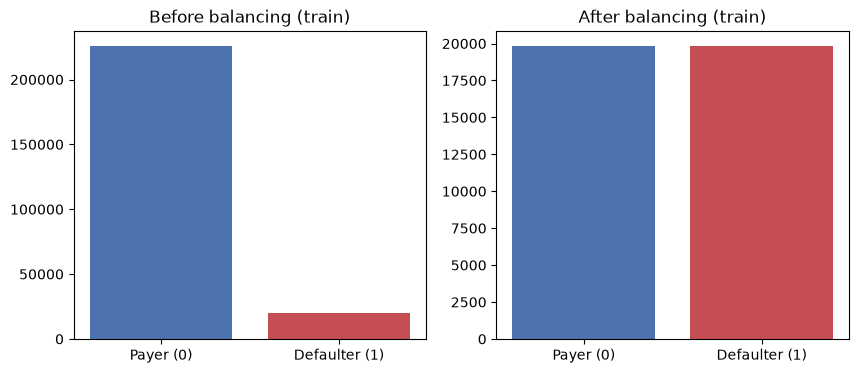

In [8]:
rng = np.random.RandomState(SEED)
pos = np.where(y_tr==1)[0]; neg = rng.choice(np.where(y_tr==0)[0], size=len(pos), replace=False)
idx = rng.permutation(np.concatenate([pos,neg]))
Xb, yb = X_tr[idx], y_tr[idx]
print('Balanced train:', Xb.shape, '| class counts:', dict(zip(*np.unique(yb, return_counts=True))))
fig,ax=plt.subplots(1,2,figsize=(10,4))
for a,(lab,arr) in zip(ax,[('Before balancing (train)',y_tr),('After balancing (train)',yb)]):
    u,cn=np.unique(arr, return_counts=True); a.bar(['Payer (0)','Defaulter (1)'], cn, color=['#4c72b0','#c44e52']); a.set_title(lab)
save('03_balanced_target'); plt.show()

## Step 7: Deep learning model (Keras)
A feed-forward network with batch normalization and dropout, trained with Adam and binary cross-entropy on the balanced training set, with 15% of it held out for validation and early stopping.

In [9]:
model = keras.Sequential([
    layers.Input(shape=(Xb.shape[1],)),
    layers.Dense(128, activation='relu'), layers.BatchNormalization(), layers.Dropout(0.3),
    layers.Dense(64, activation='relu'), layers.BatchNormalization(), layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
              metrics=['accuracy', keras.metrics.Recall(name='recall'), keras.metrics.AUC(name='auc')])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        12,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,065 (94.00 KB)

 Trainable params: 23,681 (92.50 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/25


132/132 - 23s - 175ms/step - accuracy: 0.5989 - auc: 0.6328 - loss: 0.7060 - recall: 0.6487 - val_accuracy: 0.6475 - val_auc: 0.7082 - val_loss: 0.6366 - val_recall: 0.5269


Epoch 2/25


132/132 - 5s - 36ms/step - accuracy: 0.6418 - auc: 0.6932 - loss: 0.6406 - recall: 0.6362 - val_accuracy: 0.6650 - val_auc: 0.7250 - val_loss: 0.6166 - val_recall: 0.6051


Epoch 3/25


132/132 - 4s - 31ms/step - accuracy: 0.6549 - auc: 0.7088 - loss: 0.6268 - recall: 0.6478 - val_accuracy: 0.6709 - val_auc: 0.7292 - val_loss: 0.6122 - val_recall: 0.6406


... (20 outputs left out)

Epoch 14/25


132/132 - 2s - 17ms/step - accuracy: 0.6857 - auc: 0.7490 - loss: 0.5934 - recall: 0.6922 - val_accuracy: 0.6761 - val_auc: 0.7358 - val_loss: 0.6060 - val_recall: 0.6504


Epoch 15/25


132/132 - 2s - 18ms/step - accuracy: 0.6854 - auc: 0.7503 - loss: 0.5915 - recall: 0.6946 - val_accuracy: 0.6791 - val_auc: 0.7348 - val_loss: 0.6067 - val_recall: 0.6511


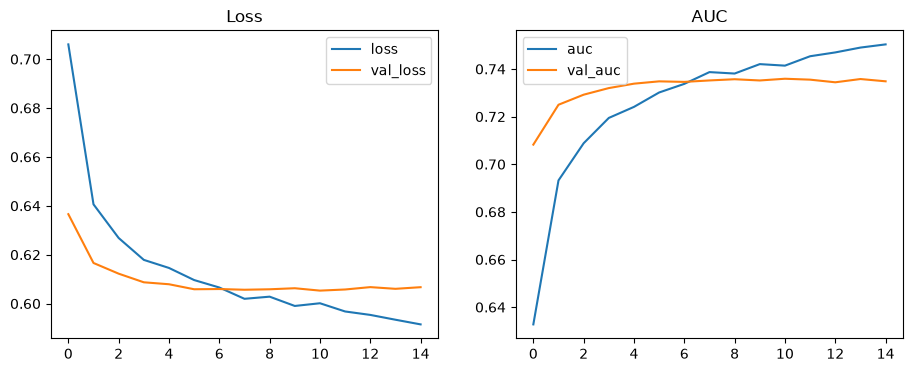

In [10]:
es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
hist = model.fit(Xb, yb, validation_split=0.15, epochs=25, batch_size=256, callbacks=[es], verbose=2)
h = pd.DataFrame(hist.history)
fig,ax=plt.subplots(1,2,figsize=(11,4))
h[['loss','val_loss']].plot(ax=ax[0], title='Loss'); h[['auc','val_auc']].plot(ax=ax[1], title='AUC')
save('04_training_curves'); plt.show()

## Step 8: Sensitivity (recall of defaulters) on the untouched test set

Sensitivity (TPR / recall): 0.6661   [TP=3307, FN=1658]
Specificity (TNR):          0.6855   [TN=38756, FP=17782]
              precision    recall  f1-score   support

       Payer      0.959     0.685     0.799     56538
   Defaulter      0.157     0.666     0.254      4965

    accuracy                          0.684     61503
   macro avg      0.558     0.676     0.527     61503
weighted avg      0.894     0.684     0.755     61503



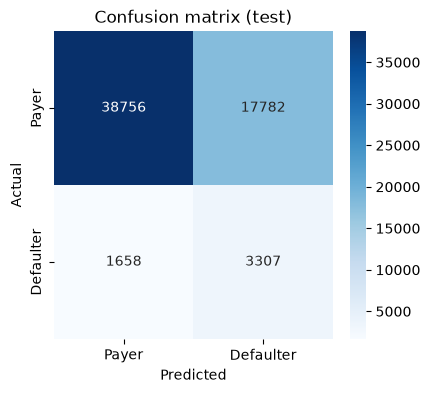

In [11]:
prob = model.predict(X_te, batch_size=2048, verbose=0).ravel()
pred = (prob>=0.5).astype(int)
tn,fp,fn,tp = confusion_matrix(y_te, pred).ravel()
sensitivity = tp/(tp+fn); specificity = tn/(tn+fp)
print(f'Sensitivity (TPR / recall): {sensitivity:.4f}   [TP={tp}, FN={fn}]')
print(f'Specificity (TNR):          {specificity:.4f}   [TN={tn}, FP={fp}]')
print(classification_report(y_te, pred, target_names=['Payer','Defaulter'], digits=3))
plt.figure(figsize=(4.5,4)); sns.heatmap(confusion_matrix(y_te,pred), annot=True, fmt='d', cmap='Blues', xticklabels=['Payer','Defaulter'], yticklabels=['Payer','Defaulter']); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion matrix (test)'); save('05_confusion_matrix'); plt.show()

Because the training set was balanced, the model flags many applicants as risky: sensitivity is far above what a majority-class model gets (0%), at the cost of lower specificity and precision. That trade-off is typical when missing a defaulter is costlier than rejecting a good applicant.

## Step 9: Area under the ROC curve

ROC-AUC (test): 0.7361


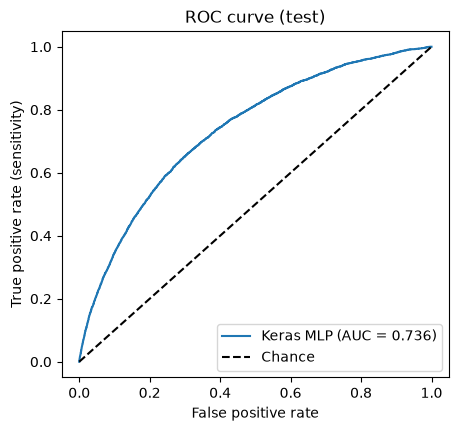

In [12]:
auc = roc_auc_score(y_te, prob); fpr,tpr,_ = roc_curve(y_te, prob)
print(f'ROC-AUC (test): {auc:.4f}')
plt.figure(figsize=(5,4.5)); plt.plot(fpr,tpr,label=f'Keras MLP (AUC = {auc:.3f})'); plt.plot([0,1],[0,1],'k--',label='Chance'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate (sensitivity)'); plt.title('ROC curve (test)'); plt.legend(); save('06_roc_curve'); plt.show()

## Final metrics summary

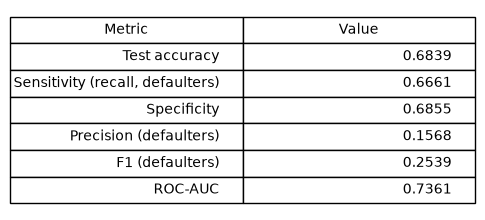

,Metric,Value
0,Test accuracy,0.6839
1,"Sensitivity (recall, defaulters)",0.6661
2,Specificity,0.6855
3,Precision (defaulters),0.1568
4,F1 (defaulters),0.2539
5,ROC-AUC,0.7361


In [13]:
res = pd.DataFrame({'Metric':['Test accuracy','Sensitivity (recall, defaulters)','Specificity','Precision (defaulters)','F1 (defaulters)','ROC-AUC'],
  'Value':[accuracy_score(y_te,pred), sensitivity, specificity, precision_score(y_te,pred), f1_score(y_te,pred), auc]}).round(4)
json.dump({r.Metric:float(r.Value) for r in res.itertuples()}, open('metrics.json','w'), indent=1)
fig,ax=plt.subplots(figsize=(6,2.6)); ax.axis('off'); t=ax.table(cellText=res.values, colLabels=res.columns, loc='center'); t.scale(1,1.6); t.auto_set_font_size(False); t.set_fontsize(10)
save('07_metrics_table'); plt.show(); res

## Conclusions
* The target is ~8% positive; balancing the training data (under-sampling) lets the network learn the minority class.
* The Keras MLP reaches the sensitivity and ROC-AUC reported above on a realistic, untouched 20% test split. An AUC around 0.7 is typical for this dataset with application-table features only (no bureau/previous-application tables).
* Improvements: join the other tables, use SMOTE or class weights on the full data, tune the decision threshold, and try gradient boosting as a baseline.